# Regressão linear simples na evolução da apuração — Presidente 2026 (1º turno)

Este notebook usa o histórico da apuração divulgado pelo G1 (04 e 05/10/2026) para ajustar uma **regressão linear simples**:

- **x** = `pct_urnas_apuradas` (percentual de urnas apuradas no momento do snapshot)
- **y** = percentual de votos válidos do candidato

Analisamos dois candidatos: **Flávio Bolsonaro**, que terminou em primeiro lugar, e **Lula**, o segundo colocado.

> **Observação metodológica.** A evolução da apuração não é linear: a ordem em que as urnas chegam depende da região (capitais e Sul/Sudeste costumam vir antes, Norte/Nordeste depois), então a curva muda de inclinação ao longo da noite. Mesmo assim, o objetivo aqui é **acadêmico**: aplicar e interpretar a regressão linear simples passo a passo, e discutir onde ela funciona e onde falha.

## 1. Dependências

O `.venv` do projeto já tem `pandas` e `numpy`. Para os gráficos e para conferir o ajuste com uma biblioteca pronta, precisamos de `matplotlib` e `scikit-learn`. Rode a célula abaixo uma vez (depois pode comentá-la).

In [1]:
%pip install -q matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import unicodedata
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 2. Carregando os dados

O CSV "largo" tem uma linha por snapshot da apuração e uma coluna `pct_<NOME>` e `votos_<NOME>` por candidato. Os nomes das colunas têm espaços e acentos (por exemplo `pct_FLAVIO BOLSONARO`), o que é incômodo no código. Por isso **sanitizamos os nomes só aqui dentro do notebook**: minúsculas, sem acento e com `_` no lugar de espaços. O arquivo original não é alterado.

In [3]:
CAMINHO_CSV = "../data/processed/apuracao_largo.csv"

def sanitizar(nome: str) -> str:
    """'pct_FLAVIO BOLSONARO' -> 'pct_flavio_bolsonaro'"""
    sem_acento = unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^0-9a-z]+", "_", sem_acento.lower()).strip("_")

bruto = pd.read_csv(CAMINHO_CSV, parse_dates=["datetime"])
bruto.columns = [sanitizar(c) for c in bruto.columns]

print(f"{len(bruto)} snapshots, {bruto.shape[1]} colunas")
bruto.columns.tolist()

383 snapshots, 32 colunas


['datetime',
 'pct_urnas_apuradas',
 'pct_brancos',
 'pct_nulos',
 'pct_abstencao',
 'situacao',
 'pct_lula',
 'votos_lula',
 'pct_renan_santos',
 'votos_renan_santos',
 'pct_hertz_dias',
 'votos_hertz_dias',
 'pct_edmilson_costa',
 'votos_edmilson_costa',
 'pct_flavio_bolsonaro',
 'votos_flavio_bolsonaro',
 'pct_clariana_barao',
 'votos_clariana_barao',
 'pct_leonardo_avalanche',
 'votos_leonardo_avalanche',
 'pct_rui_costa_pimenta',
 'votos_rui_costa_pimenta',
 'pct_zema',
 'votos_zema',
 'pct_veterinario_wilson_grassi',
 'votos_veterinario_wilson_grassi',
 'pct_ronaldo_caiado',
 'votos_ronaldo_caiado',
 'pct_escritor_augusto_cury',
 'votos_escritor_augusto_cury',
 'pct_samara',
 'votos_samara']

Ficamos só com as colunas que interessam. Também removemos snapshots repetidos com o mesmo `pct_urnas_apuradas` (por exemplo, o 100% "Parcial" e o 100% "Final" aparecem duas vezes), mantendo o último de cada valor, para que nenhum ponto pese em dobro no ajuste.

In [4]:
COL_X = "pct_urnas_apuradas"
CANDIDATOS = {
    "Flávio Bolsonaro": "pct_flavio_bolsonaro",
    "Lula": "pct_lula",
}
CORES = {"Flávio Bolsonaro": "#1f5fbf", "Lula": "#c8102e"}

df = (
    bruto[["datetime", COL_X, *CANDIDATOS.values()]]
    .dropna()
    .sort_values("datetime")
    .drop_duplicates(subset=COL_X, keep="last")
    .reset_index(drop=True)
)

print(f"{len(df)} pontos após remover duplicados")
df.describe().round(2)

247 pontos após remover duplicados


,datetime,pct_urnas_apuradas,pct_flavio_bolsonaro,pct_lula
count,247,247.00,247.00,247.00
mean,2026-10-04 20:37:01.955465,80.30,47.96,44.06
min,2026-10-04 17:21:16,1.23,47.03,40.66
25%,2026-10-04 20:18:26.500000,90.28,47.16,43.97
50%,2026-10-04 20:53:27,95.78,47.57,44.52
75%,2026-10-04 21:28:17.500000,99.34,48.04,45.01
max,2026-10-05 12:51:05,100.00,51.22,45.16
std,NaN,34.04,1.13,1.32


### Resultado final (o "gabarito")

O último snapshot, com 100% das urnas apuradas, é o resultado oficial. Vamos usá-lo para avaliar as previsões da regressão.

In [5]:
final = df.iloc[-1]
RESULTADO_FINAL = {nome: final[col] for nome, col in CANDIDATOS.items()}
print(f"Urnas apuradas: {final[COL_X]}%")
for nome, pct in RESULTADO_FINAL.items():
    print(f"  {nome}: {pct:.2f}% dos votos válidos")

Urnas apuradas: 100.0%
  Flávio Bolsonaro: 47.03% dos votos válidos
  Lula: 45.16% dos votos válidos


## 3. Visualizando os dados

Antes de ajustar qualquer modelo, olhamos o gráfico de dispersão de **x** (urnas apuradas) contra **y** (percentual do candidato).

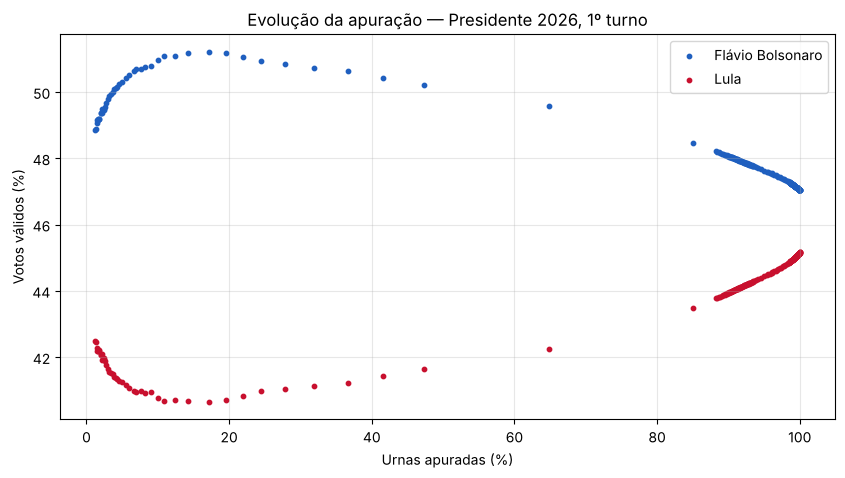

In [6]:
fig, ax = plt.subplots()
for nome, col in CANDIDATOS.items():
    ax.scatter(df[COL_X], df[col], s=10, color=CORES[nome], label=nome)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title("Evolução da apuração — Presidente 2026, 1º turno")
ax.legend()
plt.show()

Já dá para ver que Flávio começa mais alto e cai, enquanto Lula começa mais baixo e sobe, e que as curvas se curvam no final. A reta vai capturar a **tendência média**, não o formato exato.

## 4. Regressão linear simples: a teoria

O modelo é

$$\hat{y} = \beta_0 + \beta_1 x$$

em que $\beta_0$ é o intercepto (valor previsto quando $x = 0$) e $\beta_1$ é a inclinação (quanto $y$ muda, em pontos percentuais, a cada 1 ponto percentual a mais de urnas apuradas).

Pelo método dos **mínimos quadrados ordinários**, os coeficientes que minimizam $\sum (y_i - \hat{y}_i)^2$ são

$$\beta_1 = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2}, \qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

E o coeficiente de determinação, que mede a fração da variância de $y$ explicada pela reta, é

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

Vamos implementar essas fórmulas "na mão" com `numpy` e depois conferir com o `scikit-learn`.

In [7]:
def ajustar_mmq(x, y):
    """Mínimos quadrados ordinários pelas fórmulas fechadas. Retorna (beta0, beta1)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_med, y_med = x.mean(), y.mean()
    beta1 = np.sum((x - x_med) * (y - y_med)) / np.sum((x - x_med) ** 2)
    beta0 = y_med - beta1 * x_med
    return beta0, beta1

def r2(y, y_prev):
    y = np.asarray(y, dtype=float)
    return 1 - np.sum((y - y_prev) ** 2) / np.sum((y - y.mean()) ** 2)

## 5. Flávio Bolsonaro (1º colocado)

### 5.1 Ajuste com as fórmulas

In [8]:
x = df[COL_X].to_numpy()
y_flavio = df[CANDIDATOS["Flávio Bolsonaro"]].to_numpy()

b0_f, b1_f = ajustar_mmq(x, y_flavio)
y_prev_f = b0_f + b1_f * x

print(f"Intercepto (β0): {b0_f:.4f}")
print(f"Inclinação (β1): {b1_f:.6f}")
print(f"R²:              {r2(y_flavio, y_prev_f):.4f}")
print(f"RMSE:            {np.sqrt(mean_squared_error(y_flavio, y_prev_f)):.4f} p.p.")
print()
print(f"Equação: ŷ = {b0_f:.3f} {'+' if b1_f >= 0 else '-'} {abs(b1_f):.5f} · x")

Intercepto (β0): 50.3657
Inclinação (β1): -0.029963
R²:              0.8172


RMSE:            0.4814 p.p.

Equação: ŷ = 50.366 - 0.02996 · x


### 5.2 Conferindo com o scikit-learn

O `LinearRegression` espera `X` como matriz (n linhas × 1 coluna), por isso o `reshape(-1, 1)`. Os coeficientes devem bater com os calculados acima.

In [9]:
modelo_f = LinearRegression().fit(x.reshape(-1, 1), y_flavio)
print(f"sklearn β0 = {modelo_f.intercept_:.4f}   β1 = {modelo_f.coef_[0]:.6f}")
print(f"sklearn R² = {modelo_f.score(x.reshape(-1, 1), y_flavio):.4f}")
assert np.isclose(modelo_f.intercept_, b0_f) and np.isclose(modelo_f.coef_[0], b1_f)
print("Coeficientes idênticos aos das fórmulas ✔")

sklearn β0 = 50.3657   β1 = -0.029963
sklearn R² = 0.8172
Coeficientes idênticos aos das fórmulas ✔


### 5.3 Interpretação

- **β1 negativo** significa que, em média, a cada 1 p.p. a mais de urnas apuradas o percentual de Flávio caiu |β1| p.p.: as urnas que chegaram depois eram menos favoráveis a ele.
- **β0** é o percentual que a reta "prevê" com 0% das urnas. Não tem significado real (não existe resultado com zero urnas), é só onde a reta corta o eixo.
- **R²** diz quanto da variação do percentual ao longo da noite a reta explica.

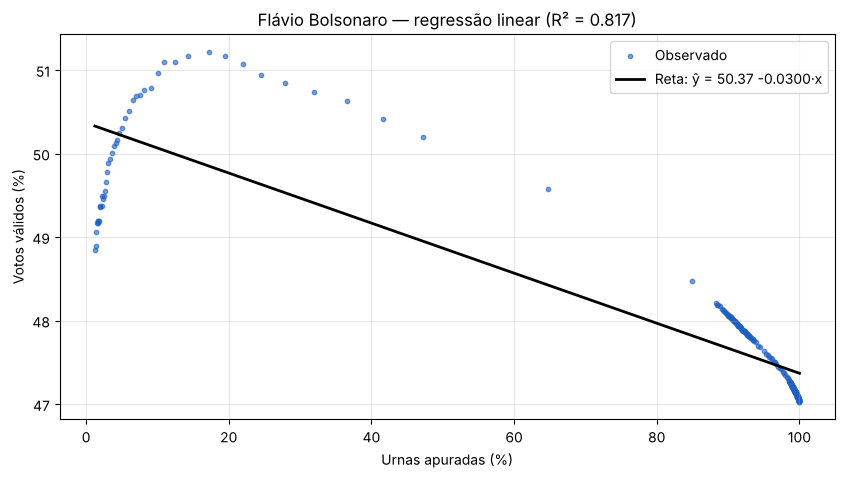

In [10]:
fig, ax = plt.subplots()
ax.scatter(x, y_flavio, s=10, color=CORES["Flávio Bolsonaro"], alpha=0.6, label="Observado")
ax.plot(x, y_prev_f, color="black", lw=2, label=f"Reta: ŷ = {b0_f:.2f} {b1_f:+.4f}·x")
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title(f"Flávio Bolsonaro — regressão linear (R² = {r2(y_flavio, y_prev_f):.3f})")
ax.legend()
plt.show()

### 5.4 Extrapolando para 100% das urnas

Substituímos x = 100 na equação e comparamos com o resultado oficial. Aqui o modelo usou **todos** os pontos, inclusive os do fim da apuração, então é um teste fácil.

In [11]:
prev_100_f = b0_f + b1_f * 100
print(f"Previsão da reta em 100%: {prev_100_f:.2f}%")
print(f"Resultado oficial:        {RESULTADO_FINAL['Flávio Bolsonaro']:.2f}%")
print(f"Erro:                     {prev_100_f - RESULTADO_FINAL['Flávio Bolsonaro']:+.2f} p.p.")

Previsão da reta em 100%: 47.37%
Resultado oficial:        47.03%
Erro:                     +0.34 p.p.


### 5.5 Resíduos

Os resíduos ($y_i - \hat{y}_i$) mostram o que a reta não captura. Se o modelo linear fosse adequado, eles se espalhariam aleatoriamente em torno de zero. Um padrão em forma de curva indica que a relação real não é linear.

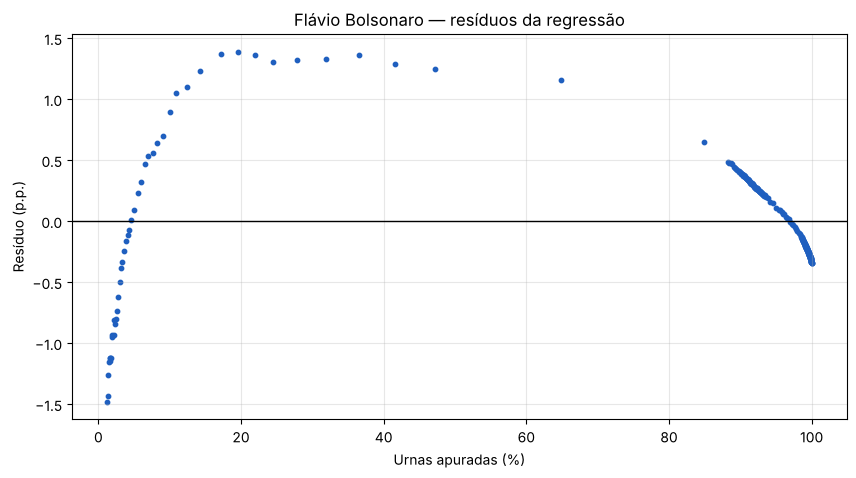

In [12]:
fig, ax = plt.subplots()
ax.scatter(x, y_flavio - y_prev_f, s=10, color=CORES["Flávio Bolsonaro"])
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Resíduo (p.p.)")
ax.set_title("Flávio Bolsonaro — resíduos da regressão")
plt.show()

## 6. Lula (2º colocado)

Repetimos exatamente os mesmos passos para Lula, agora usando uma função para não duplicar código.

In [13]:
def analisar(nome, x, y):
    b0, b1 = ajustar_mmq(x, y)
    y_prev = b0 + b1 * x
    prev_100 = b0 + b1 * 100
    return {
        "candidato": nome,
        "beta0": b0,
        "beta1": b1,
        "R2": r2(y, y_prev),
        "RMSE": np.sqrt(mean_squared_error(y, y_prev)),
        "previsto_100": prev_100,
        "real_100": RESULTADO_FINAL[nome],
        "erro_pp": prev_100 - RESULTADO_FINAL[nome],
    }

y_lula = df[CANDIDATOS["Lula"]].to_numpy()
res_lula = analisar("Lula", x, y_lula)
b0_l, b1_l = res_lula["beta0"], res_lula["beta1"]

print(f"Equação: ŷ = {b0_l:.3f} {'+' if b1_l >= 0 else '-'} {abs(b1_l):.5f} · x")
print(f"R² = {res_lula['R2']:.4f}   RMSE = {res_lula['RMSE']:.4f} p.p.")
print(f"Previsão em 100%: {res_lula['previsto_100']:.2f}%  |  oficial: {res_lula['real_100']:.2f}%  |  erro: {res_lula['erro_pp']:+.2f} p.p.")

Equação: ŷ = 41.135 + 0.03637 · x
R² = 0.8789   RMSE = 0.4587 p.p.
Previsão em 100%: 44.77%  |  oficial: 45.16%  |  erro: -0.39 p.p.


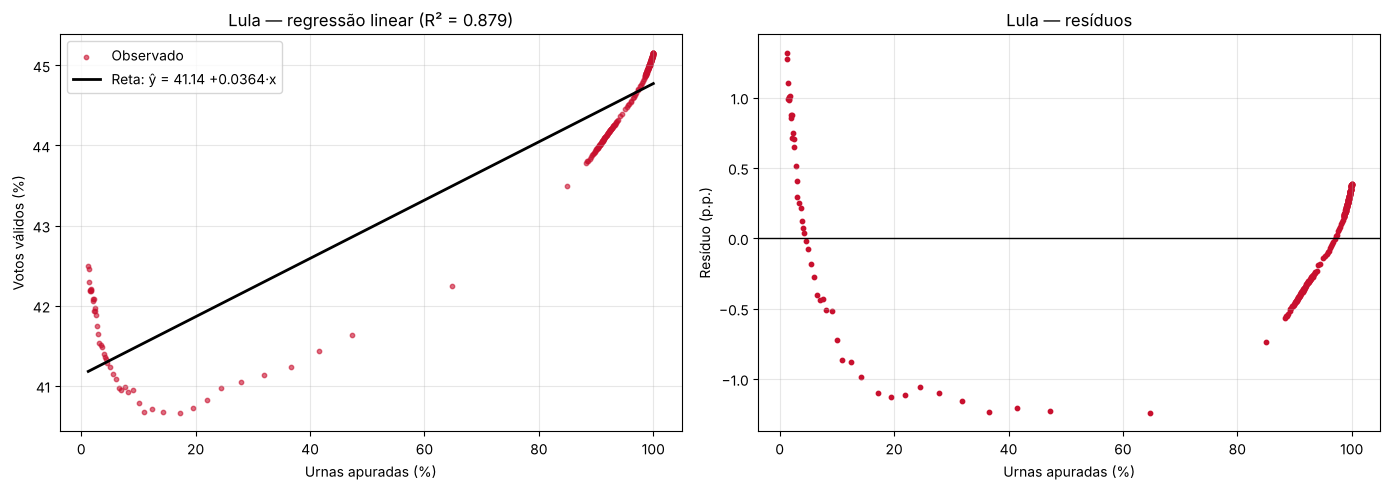

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(x, y_lula, s=10, color=CORES["Lula"], alpha=0.6, label="Observado")
ax.plot(x, b0_l + b1_l * x, color="black", lw=2, label=f"Reta: ŷ = {b0_l:.2f} {b1_l:+.4f}·x")
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title(f"Lula — regressão linear (R² = {res_lula['R2']:.3f})")
ax.legend()

ax = axes[1]
ax.scatter(x, y_lula - (b0_l + b1_l * x), s=10, color=CORES["Lula"])
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Resíduo (p.p.)")
ax.set_title("Lula — resíduos")

plt.tight_layout()
plt.show()

## 7. Comparando os dois candidatos

In [15]:
resumo = pd.DataFrame([analisar(nome, x, df[col].to_numpy()) for nome, col in CANDIDATOS.items()])
resumo.set_index("candidato").round(4)

,beta0,beta1,R2,RMSE,previsto_100,real_100,erro_pp
candidato,,,,,,,
Flávio Bolsonaro,50.3657,-0.0300,0.8172,0.4814,47.3693,47.03,0.3393
Lula,41.1353,0.0364,0.8789,0.4587,44.7726,45.16,-0.3874


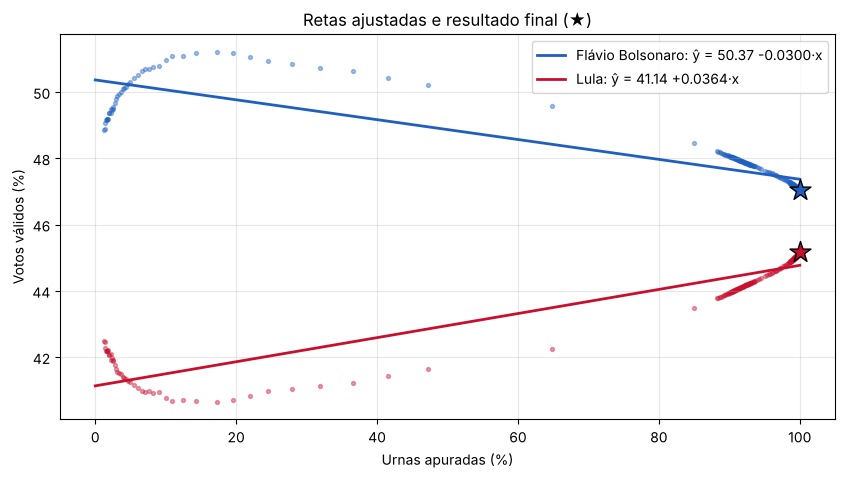

In [16]:
fig, ax = plt.subplots()
for nome, col in CANDIDATOS.items():
    b0, b1 = ajustar_mmq(x, df[col])
    ax.scatter(x, df[col], s=8, color=CORES[nome], alpha=0.4)
    ax.plot([0, 100], [b0, b0 + b1 * 100], color=CORES[nome], lw=2, label=f"{nome}: ŷ = {b0:.2f} {b1:+.4f}·x")
    ax.scatter([100], [RESULTADO_FINAL[nome]], marker="*", s=250, color=CORES[nome], edgecolor="black", zorder=5)
ax.set_xlabel("Urnas apuradas (%)")
ax.set_ylabel("Votos válidos (%)")
ax.set_title("Retas ajustadas e resultado final (★)")
ax.legend()
plt.show()

## 8. Dá para prever o resultado no meio da apuração?

O teste mais interessante é **treinar só com o começo da apuração** e prever o resultado em 100%, como se estivéssemos na noite da eleição sem saber o final. Treinamos com os pontos até 30%, 40% e 50% das urnas apuradas e comparamos a previsão com o resultado oficial.

Como referência, comparamos também com o "modelo ingênuo": simplesmente usar o último percentual conhecido como previsão final.

In [17]:
CORTES = [30, 40, 50]

linhas = []
for corte in CORTES:
    treino = df[df[COL_X] <= corte]
    for nome, col in CANDIDATOS.items():
        b0, b1 = ajustar_mmq(treino[COL_X], treino[col])
        prev = b0 + b1 * 100
        ultimo = treino[col].iloc[-1]
        real = RESULTADO_FINAL[nome]
        linhas.append({
            "treino_ate_%": corte,
            "candidato": nome,
            "n_pontos": len(treino),
            "beta1": b1,
            "previsto_100": prev,
            "ultimo_valor": ultimo,
            "real_100": real,
            "erro_reta_pp": prev - real,
            "erro_ingenuo_pp": ultimo - real,
        })

previsoes = pd.DataFrame(linhas)
previsoes.round(3)

,treino_ate_%,candidato,n_pontos,beta1,previsto_100,ultimo_valor,real_100,erro_reta_pp,erro_ingenuo_pp
0,30,Flávio Bolsonaro,41,0.087,58.209,50.85,47.03,11.179,3.82
1,30,Lula,41,-0.062,35.702,41.05,45.16,-9.458,-4.11
2,40,Flávio Bolsonaro,43,0.058,55.469,50.63,47.03,8.439,3.60
3,40,Lula,43,-0.039,37.857,41.23,45.16,-7.303,-3.93
4,50,Flávio Bolsonaro,45,0.035,53.293,50.20,47.03,6.263,3.17
5,50,Lula,45,-0.021,39.551,41.63,45.16,-5.609,-3.53


Vale olhar também **quem a reta diz que ganha**: se a inclinação for forte o bastante, ela pode prever uma virada que não aconteceu (ou acertar uma que aconteceu).

In [18]:
for corte in CORTES:
    p = previsoes[previsoes["treino_ate_%"] == corte].set_index("candidato")["previsto_100"]
    lider = p.idxmax()
    print(f"Treino até {corte}%: Flávio {p['Flávio Bolsonaro']:.2f}% × Lula {p['Lula']:.2f}%  →  líder previsto: {lider}")
real_lider = max(RESULTADO_FINAL, key=RESULTADO_FINAL.get)
print(f"Resultado oficial: líder = {real_lider}")

Treino até 30%: Flávio 58.21% × Lula 35.70%  →  líder previsto: Flávio Bolsonaro
Treino até 40%: Flávio 55.47% × Lula 37.86%  →  líder previsto: Flávio Bolsonaro
Treino até 50%: Flávio 53.29% × Lula 39.55%  →  líder previsto: Flávio Bolsonaro
Resultado oficial: líder = Flávio Bolsonaro


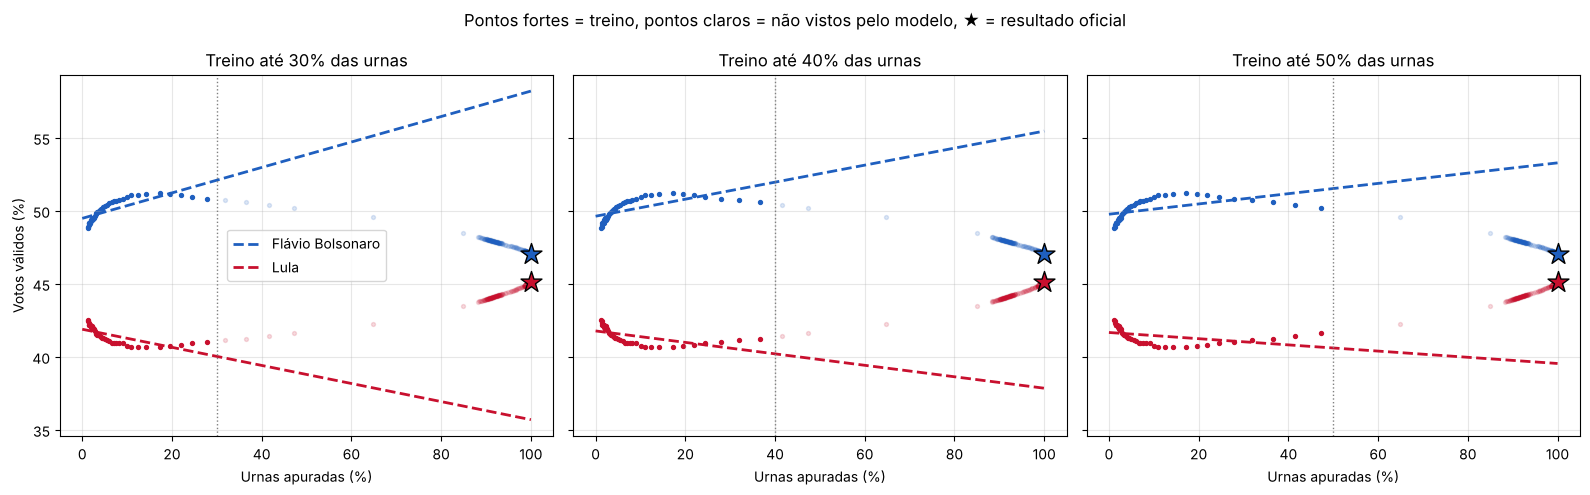

In [19]:
fig, axes = plt.subplots(1, len(CORTES), figsize=(16, 5), sharey=True)
for ax, corte in zip(axes, CORTES):
    treino = df[df[COL_X] <= corte]
    teste = df[df[COL_X] > corte]
    for nome, col in CANDIDATOS.items():
        b0, b1 = ajustar_mmq(treino[COL_X], treino[col])
        ax.scatter(treino[COL_X], treino[col], s=8, color=CORES[nome])
        ax.scatter(teste[COL_X], teste[col], s=8, color=CORES[nome], alpha=0.15)
        ax.plot([0, 100], [b0, b0 + b1 * 100], color=CORES[nome], lw=2, ls="--", label=nome)
        ax.scatter([100], [RESULTADO_FINAL[nome]], marker="*", s=250, color=CORES[nome], edgecolor="black", zorder=5)
    ax.axvline(corte, color="gray", ls=":", lw=1)
    ax.set_title(f"Treino até {corte}% das urnas")
    ax.set_xlabel("Urnas apuradas (%)")
axes[0].set_ylabel("Votos válidos (%)")
axes[0].legend()
plt.suptitle("Pontos fortes = treino, pontos claros = não vistos pelo modelo, ★ = resultado oficial")
plt.tight_layout()
plt.show()

## 9. Limitações

- **A relação não é linear.** O padrão curvo nos resíduos mostra que a inclinação muda ao longo da apuração. A reta resume a tendência média, mas erra sistematicamente em trechos específicos.
- **Os pontos não são independentes.** Cada snapshot é a soma acumulada dos anteriores mais algumas urnas novas, então pontos vizinhos são quase iguais. Isso viola a hipótese de independência dos erros, e medidas como erro padrão e p-valor ficariam otimistas demais.
- **A ordem de chegada das urnas não é aleatória.** A variação do percentual vem de *quais* regiões são apuradas em cada momento, algo que o x (percentual de urnas) não captura.
- **Os pontos estão concentrados no fim.** Metade dos snapshots tem mais de ~96% das urnas apuradas, porque o G1 atualiza com mais frequência no final. A reta ajustada com todos os dados é "puxada" por esse trecho, o que ajuda a extrapolação para 100% mas esconde o comportamento do começo.
- **Extrapolar é arriscado.** Prever 100% a partir de 30% significa usar a reta muito fora do intervalo de treino.

Mesmo com essas limitações, o exercício mostra bem como estimar, interpretar e avaliar uma regressão linear simples.

## 10. Conclusões

- **Inclinações.** Com todos os dados, a reta de Flávio tem β1 ≈ −0,030 (perde cerca de 0,3 p.p. a cada 10 p.p. de urnas apuradas) e a de Lula tem β1 ≈ +0,036. É o padrão clássico: as urnas que chegam primeiro favorecem um candidato e as últimas, o outro.
- **R².** Os ajustes explicam cerca de 82% (Flávio) e 88% (Lula) da variação do percentual. É alto, mas parte disso vem da concentração de pontos perto de 100%.
- **Extrapolação com todos os dados.** A reta prevê 47,37% para Flávio (real: 47,03%) e 44,77% para Lula (real: 45,16%), erros de menos de 0,4 p.p. Mas é um teste fácil, porque o modelo já "viu" o final.
- **Previsão no meio da apuração.** Treinando só até 30–50% das urnas, a inclinação tem **sinal oposto**: no começo Flávio ainda subia e Lula caía. A reta acerta o vencedor (Flávio), mas erra o percentual em 6 a 11 p.p., bem pior que o modelo ingênuo (3 a 4 p.p.). É a demonstração prática de que a curva não é linear e de que extrapolar uma tendência local é perigoso.